# Project: Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders
#### Dataset: banking77 

# Banking77 dataset

Online banking customer queries labeled with one of 77 fine-grained intents (single-label intent classification).

Source: PolyAI/banking77 on the Hugging Face Hub
Pinned revision: 0b62e79500b84f0fff5a36a4404028f48fbc8621
Download: python scripts/download_data.py 

### Main Files:

| File | Description | Format |
|------|------|--------|
| data/raw/train.parquet | Training split (10,003 queries)  | text, label |
| data/raw/test.parquet | Test split (3,080 queries) | text, label |
| data/raw/label_names.json | 	Intent names, indexed by label id | JSON list of 77 strings |

#### Columns
| Column   | Type | Description |
|----------|-------------|--------|
|  text | string | 	The customer query, e.g. I am still waiting on my card? |
|  label  | int (0-76) | Intent id; index into label_names.json (e.g. 11 -> card_arrival) |

label_name is added at load time in the notebooks (label_names[label]); it is not stored in the parquet files.

* 13,083 queries in total across 77 intents (train + test).
* Some intent names are inconsistent in the original data: Refund_not_showing_up (capital R) and reverted_card_payment? (trailing ?). Keep the original names as the id mapping and clean them only for display.
* Many intents are semantically close (e.g. card_payment_not_recognised vs. card_payment_wrong_exchange_rate), which is the main source of classification errors.
* Class balance, query lengths, overlap and similar-intent pairs are documented in notebooks/eda.ipynb.


### Import Libraries

* Run `python scripts/download_data.py` once first; this notebook only reads `data/raw/`.

In [4]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 100)

ROOT = Path.cwd()
if ROOT.name == "notebooks":      # works from notebooks/ (VS Code) or repo root (Colab)
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

assert (RAW / "train.parquet").exists(), "Run scripts/download_data.py first"

### Load

In [20]:
train = pd.read_parquet(RAW / "train.parquet")
test = pd.read_parquet(RAW / "test.parquet")
label_names = json.load(open(RAW / "label_names.json"))

for df in (train, test):
    df["label_name"] = df["label"].map(lambda i: label_names[i])

print("train:", train.shape, "| test:", test.shape, "| labels:", len(label_names))
train.sample(8, random_state=0)

train: (10003, 3) | test: (3080, 3) | labels: 77


,text,label,label_name
7145,How can I transfer money to a beneficiary?,7,beneficiary_not_allowed
834,How is my ATM deposit not available yet?,46,pending_cash_withdrawal
3585,There is a vendor name I don't recognize on a payment from my account. I don't think I made this...,16,card_payment_not_recognised
4497,My statement shows charges for things I never purchased. Were my account details stolen?,22,compromised_card
7046,"Hi, I am interested buying crypto currency but unable to purchase it through the application. I ...",7,beneficiary_not_allowed
8588,My topping up didn't go through.,59,top_up_failed
377,How do you decide what your exchange rates are?,32,exchange_rate
1453,I would like to exchange currency What types are there?,33,exchange_via_app


### Check for nulls, empty texts, duplicates

In [22]:
for name, df in [("Train", train), ("Test", test)]:
    print(f"{name}: nulls={df.isna().sum().sum()}, "
          f"empty texts={(df.text.str.strip() == '').sum()}, "
          f"exact duplicate texts={df.text.duplicated().sum()}")

Train: nulls=0, empty texts=0, exact duplicate texts=0
Test: nulls=0, empty texts=0, exact duplicate texts=0


In [39]:
# Unique labels in Train, Test

print('Unique labels in train: ', train['label'].nunique())
print('Unique labels in test: ', test['label'].nunique())

Unique labels in train:  77
Unique labels in test:  77


### Label Distribution

In [24]:
tr_counts = train.label_name.value_counts()
te_counts = test.label_name.value_counts()

dist = pd.DataFrame({"train": tr_counts, "test": te_counts}).fillna(0).astype(int)
dist["train_pct"] = (dist.train / dist.train.sum() * 100).round(2)
dist["test_pct"] = (dist.test / dist.test.sum() * 100).round(2)

print(f"Train per class: min={tr_counts.min()}, median={tr_counts.median():.0f}, max={tr_counts.max()}, "
      f"Imbalance ratio={tr_counts.max() / tr_counts.min():.2f}")  # imbalance ratio = biggest class / smallest class

print(f"Test  per class: min={te_counts.min()}, max={te_counts.max()},"
      f"Imbalance ratio={te_counts.max() / te_counts.min():.2f}")

print("\nLargest train-vs-test share gap (pct points):", (dist.train_pct - dist.test_pct).abs().max().round(2))

# The smallest train class limits how large a perfectly balanced training subset can be
print("\nMax balanced examples per class available in train:", tr_counts.min())

dist.sort_values("train").head(10)

Train per class: min=35, median=127, max=187, Imbalance ratio=5.34
Test  per class: min=40, max=40,Imbalance ratio=1.00

Largest train-vs-test share gap (pct points): 0.95

Max balanced examples per class available in train: 35


,train,test,train_pct,test_pct
label_name,,,,
contactless_not_working,35,40,0.35,1.3
virtual_card_not_working,41,40,0.41,1.3
card_acceptance,59,40,0.59,1.3
card_swallowed,61,40,0.61,1.3
lost_or_stolen_card,82,40,0.82,1.3
compromised_card,86,40,0.86,1.3
atm_support,87,40,0.87,1.3
receiving_money,95,40,0.95,1.3
get_disposable_virtual_card,97,40,0.97,1.3


#### Findings:

* Train dataset: Intents range from 35 to 187 training examples. Half have more than 127.
* Train dataset: The biggest intent has about 5.3 times as many examples as the smallest (187 / 35). It is moderate, not extreme.
* Test dataset: Every intent has exactly 40 test examples (40 × 77 = 3,080). The test set is perfectly balanced.
* The biggest mismatch between train and test proportions is under one percentage point.
* A training set with the same number of examples per intent can have at most 35 per intent.
* A perfectly balanced test set gives every intent a share of 1/77, about 1.3%. In train, contactless_not_working is only 0.35% of the data (35 examples), against 1.3% in test. That intent is also where the 0.95 gap comes from: 1.30 − 0.35 = 0.95. Every other intent has a smaller gap.

### Implications on datazise split

Examples per intent (k): for example 1, 3, 5, 10, 20, 35. Every intent gets exactly k examples, but it cannot go above 35.
Total examples (N): sampled proportionally by class, so it can go up to the full 10,003, but intents stay imbalanced.
* Use k for the small sizes and add the full training set as the final point.

Validation set holdout: 20% (2000 samples)- smallest intent drops to 28 examples.

Report macro-averaged metrics (macro F1) as well as accuracy?? They reflect the per-intent performance, and they are not distorted by the train imbalance.

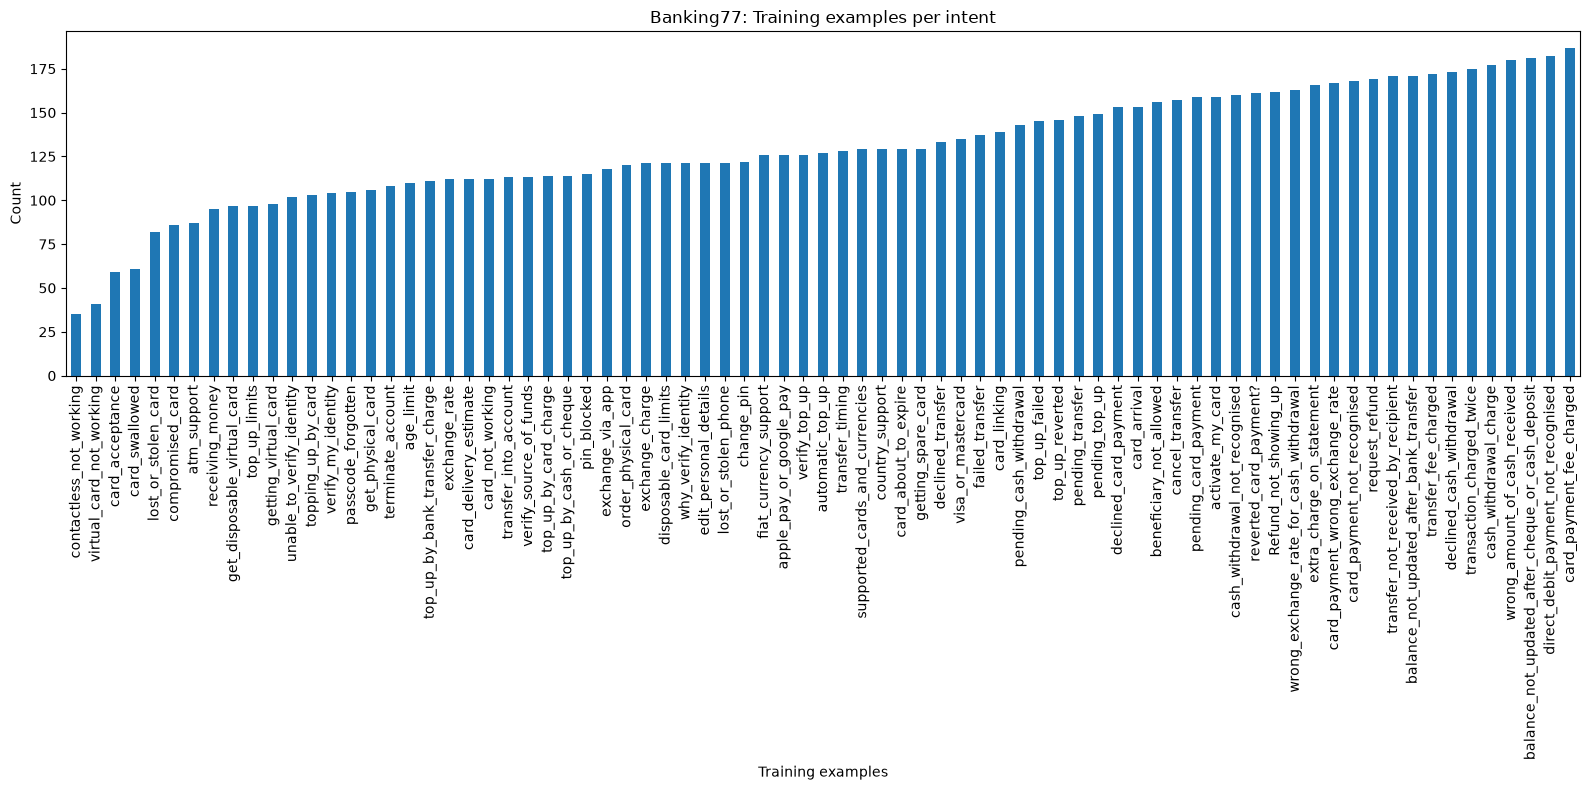

In [38]:
fig, ax = plt.subplots(figsize=(16, 8))
tr_counts.sort_values().plot(kind="bar", ax=ax)

# ax.bar_label(ax.containers[0], rotation=90, fontsize=6, padding=2)

ax.set_xlabel("Training examples")
ax.set_ylabel("Count")
ax.set_title("Banking77: Training examples per intent")

plt.xticks(rotation=90)

plt.tight_layout()
fig.savefig(FIG / "Label_distribution_train.png", dpi=150)
plt.show()

### Text length

* Useful for setting max_length for tokenization

No.of words and no. of characters in Train dataset text:

       n_words  n_chars
count  10003.0  10003.0
mean      11.9     59.5
std        7.9     40.9
min        2.0     13.0
25%        7.0     36.0
50%       10.0     47.0
75%       13.0     64.0
max       79.0    433.0

No.of words and no. of characters in Test dataset text:

       n_words  n_chars
count   3080.0   3080.0
mean      11.0     54.2
std        6.7     34.7
min        2.0     13.0
25%        7.0     35.0
50%        9.0     45.0
75%       12.0     60.0
max       69.0    368.0


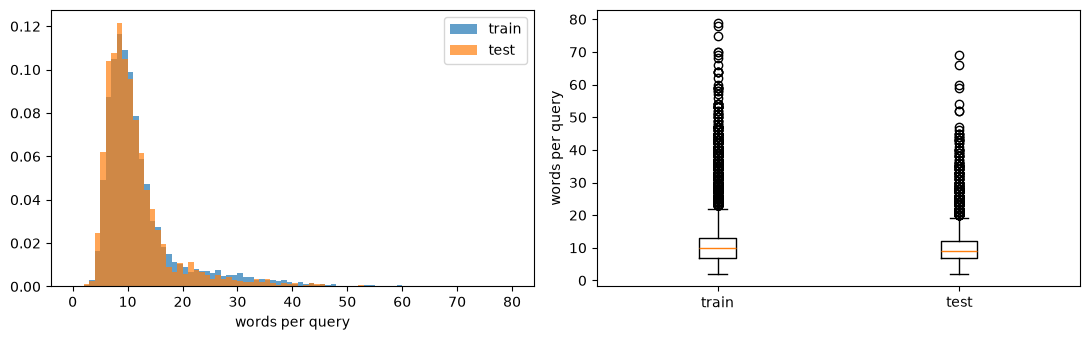

In [44]:
for df in (train, test):
    df["n_words"] = df.text.str.split().str.len()
    df["n_chars"] = df.text.str.len() # .str.len() directly on the text counts characters, including spaces and punctuation

print(f'No.of words and no. of characters in Train dataset text:\n')
print(train[["n_words", "n_chars"]].describe().round(1))

print(f'\nNo.of words and no. of characters in Test dataset text:\n')
print(test[["n_words", "n_chars"]].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
bins = range(0, int(max(train.n_words.max(), test.n_words.max())) + 2)
ax[0].hist(train.n_words, bins=bins, alpha=0.7, density=True, label="train")
ax[0].hist(test.n_words, bins=bins, alpha=0.7, density=True, label="test")
ax[0].set_xlabel("words per query"); ax[0].legend()
ax[1].boxplot([train.n_words, test.n_words], showfliers=True)
ax[1].set_xticklabels(["train", "test"])
ax[1].set_ylabel("words per query")
plt.tight_layout()
fig.savefig(FIG / "length_distribution.png", dpi=150)
plt.show()

### Explaination of Results:

On Train dataset:
* Queries are short. Half have 10 words or fewer, and three quarters have 13 or fewer. These are single customer questions, not paragraphs.
* The distribution is right-skewed.
* Outliers start around 22 words. The box spans 7 to 13 words, so its width (the interquartile range) is 6. The boxplot’s whiskers extend 1.5 × that beyond the box, up to about 13 + 9 = 22 words.
* Very short queries exist. Minimum is 2 words ( Very little context, will be hard to classify).

On Test dataset:
* Queries are short. Half have 9 words or fewer, and three quarters have 12 or fewer. Like train, these are single customer questions, not paragraphs.
* The distribution is right-skewed. The mean (11.0) is above the median (9), and the max (69 words) is far beyond the 75th percentile (12).
* Outliers start around 20 words. The box spans 7 to 12 words, so its width (the interquartile range) is 5. The boxplot's whiskers extend 1.5 × 5 = 7.5 beyond the box, up to about 12 + 7.5 = 19.5 words. 
* Very short queries exist here too. Minimum is 2 words (very little context, will be hard to classify).



In [46]:
# Text length by intent

by_class = train.groupby("label_name").n_words.agg(["mean", "median", "max"]).round(1).sort_values("mean")
print("Shortest-query intents:"); print(by_class.head(5))
print("\nLongest-query intents:"); print(by_class.tail(5))

# Check some of the longest queries
train[train.label_name == "transfer_fee_charged"].nlargest(3, "n_words")[["text", "n_words"]]

Shortest-query intents:
                    mean  median  max
label_name                           
card_acceptance      7.5     8.0   11
top_up_limits        7.7     7.0   17
passcode_forgotten   7.7     7.0   17
atm_support          7.7     8.0   13
get_physical_card    7.7     7.0   17

Longest-query intents:
                                     mean  median  max
label_name                                            
failed_transfer                      16.0    10.0   54
direct_debit_payment_not_recognised  16.0    12.0   58
pending_cash_withdrawal              16.5    11.0   64
transfer_fee_charged                 17.4    11.0   78
transfer_not_received_by_recipient   17.5    12.0   58


,text,n_words
7310,Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-refer...,78
7229,"I transferred 7,000 to a receiver outside the EU and they received a lesser amount than what I s...",68
7283,I don't appreciate the extra fees being siphoned from my account. I was helping some friends mov...,57


### Train/Test overlap and label noise

* Check if same query appearing in both train and test
* Check if same query appearing in train with different labels.

In [ ]:
norm = lambda s: s.str.lower().str.strip() # normalized version of the text (lowercased, trimmed), so "Card" and "card " count as the same query.

overlap = set(norm(train.text)) & set(norm(test.text))
print("Texts appearing in both train and test (case-insensitive):", len(overlap))

tn = train.assign(text_norm=norm(train.text))
n_labels = tn.groupby("text_norm").label.nunique()
conflicts = n_labels[n_labels > 1]
print("Identical train texts with different labels:", len(conflicts))
tn[tn.text_norm.isin(conflicts.index)].sort_values("text_norm")[["text", "label_name"]].head(20)

Texts appearing in both train and test (case-insensitive): 6
Identical train texts with different labels: 0


,text,label_name


### Explanation of Results:
* A little leakage : 6 test queries (about 0.2% of 3,080) also appear in train after lowercasing and trimming whitespace
* No query in train has conflicting labels(checked after normalizing case and whitespace).
* Exact duplicates within train and within test: 0

In [48]:
# Check the 6 overlapping queries

# Normalize the test texts the same way as the train texts
tt = test.assign(text_norm=norm(test.text))

# Keep only the test rows whose normalized text also appears in train
shared = tt[tt.text_norm.isin(overlap)]

# Attach the train label for each shared text 
check = shared.merge(
    tn[["text_norm", "label_name"]],
    on="text_norm",
    suffixes=("_test", "_train"),
)

# A True in "same_label" means train and test agree on the intent
check["same_label"] = check.label_name_test == check.label_name_train
check[["text", "label_name_test", "label_name_train", "same_label"]]


,text,label_name_test,label_name_train,same_label
0,How do I unblock my PIN?,pin_blocked,pin_blocked,True
1,\n\nWhat businesses accept this card?,card_acceptance,card_acceptance,True
2,Where can I use my card?,card_acceptance,card_acceptance,True
3,"There are a few transaction that I don't recognize, I think someone managed to get my card detai...",compromised_card,compromised_card,True
4,At which ATMs can I use this card?,atm_support,atm_support,True
5,Which cash machines will allow me to change my PIN?,change_pin,change_pin,True


### Explanation of Results

Train/test overlap:
* 6 test queries (about 0.2% of the test set) also appear in train after lowercasing and trimming whitespace.
* All 6 have the same label in train and test (pin_blocked, card_acceptance x2, compromised_card, atm_support, change_pin), so this is duplication, not label noise.
* At least one query (a card_acceptance example) begins with newline characters, so text is normalized (trimmed) before comparing.

In [ ]:
# How many queries in each split contain a newline or leading/trailing whitespace
for name, df in [("train", train), ("test", test)]:
    has_newline = df.text.str.contains("\n").sum()
    has_edge_space = (df.text != df.text.str.strip()).sum()
    print(f"{name}: with newline={has_newline}, with leading/trailing whitespace={has_edge_space}") # ??? Shoud we strip leading and trailing whitespaces?

train: with newline=10, with leading/trailing whitespace=9
test: with newline=3, with leading/trailing whitespace=3


### Intent similarity 

* Each intent is represented as one TF-IDF (Term Frequency - Inverse Document Frequency) document built from all its training queries; cosine similarity then shows which intents share vocabulary.

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

# Join all training queries of each intent into one string -> 77 "documents", one per intent
# reindex(range(77)) puts them in label-id order, so row i is intent i
class_docs = train.groupby("label")["text"].apply(" ".join).reindex(range(len(label_names)))

# Start from the built-in list and remove the negation words 
custom_stops = list(ENGLISH_STOP_WORDS - {"not", "no", "never", "cannot"})

# Configure the vectorizer
tfidf = TfidfVectorizer(ngram_range=(1, 2), stop_words=custom_stops, min_df=2, sublinear_tf=True)

# C is a sparse table: one row per intent, one column per word/phrase, cells hold TF-IDF scores
C = tfidf.fit_transform(class_docs)

# The word or phrase behind each column of C, in the same order
terms = tfidf.get_feature_names_out()

def top_terms(i, k=10):
    # C[i] is intent i's row (sparse); toarray().ravel() turns it into a plain 1D array of scores
    row = C[i].toarray().ravel()
    return [terms[j] for j in row.argsort()[::-1][:k]]

# A seeded random generator
rng = np.random.default_rng(0)

print(f"Intent -> Top terms\n")
for i in rng.choice(len(label_names), size=5, replace=False):
    print(f"{label_names[i]:45s} -> {top_terms(i)}")

Intent -> Top terms

pending_top_up                                -> ['pending', 'hour', 'half', 'topped', 'pending long', 'tried topping', 'instant', 'time today', 'customer', 'pending pending']
get_physical_card                             -> ['pin', 'card pin', 'pin pin', 'pin card', 'pin number', 'pin not', 'pin set', 'locate', 'pin don', 'pin tell']
cash_withdrawal_not_recognised                -> ['withdrawal', 'cash withdrawal', 'withdrawal didn', 'withdrawal account', 'didn make', 'app cash', 'cash', 'wallet', 'town', 'withdraw']
contactless_not_working                       -> ['try use', 'no matter', 'metro', 'working', 'payments', 'try', 'not working', 'stopped working', 'tried pay', 'matter']
topping_up_by_card                            -> ['card money', 'friends', 'disappeared', 'wallet', 'using credit', 'money disappeared', 'topped', 'credit card', 'money credit', 'card credit']


#### Explanation:

TF-IDF per intent:
* Each intent is one document made of all its training queries (77 documents); settings: unigrams and bigrams, English stop words removed, min_df=2, sublinear_tf=True (log-scaled counts so frequent words like "card" don't dominate).
* Top terms are mostly sensible topic words (e.g. withdrawal / cash withdrawal for cash_withdrawal_not_recognised; pending / hour / half for pending_top_up).
* TF-IDF favors distinctive rather than typical words, so some top terms are incidental (e.g. "metro" for contactless_not_working).
* get_physical_card is dominated by "pin" terms, suggesting vocabulary overlap with the PIN intents (to check in the similarity ranking).


In [ ]:
S = cosine_similarity(C)
np.fill_diagonal(S, 0)
iu = np.triu_indices_from(S, k=1)

# One DataFrame row per pair: the two intent names and their similarity score
pairs = pd.DataFrame({
    "intent_a": [label_names[i] for i in iu[0]], # first intent of each pair (row index)
    "intent_b": [label_names[j] for j in iu[1]], # second intent of each pair (column index)
    "cosine": S[iu].round(3), # most similar pairs first
}).sort_values("cosine", ascending=False)
pairs.head(20)

,intent_a,intent_b,cosine
2902,verify_my_identity,why_verify_identity,0.627
1805,disposable_card_limits,get_disposable_virtual_card,0.590
1214,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal,0.515
1107,card_payment_not_recognised,direct_debit_payment_not_recognised,0.467
2180,get_disposable_virtual_card,virtual_card_not_working,0.460
2148,get_disposable_virtual_card,getting_virtual_card,0.414
2890,unable_to_verify_identity,verify_my_identity,0.410
538,beneficiary_not_allowed,failed_transfer,0.398
2226,getting_spare_card,order_physical_card,0.396
2895,unable_to_verify_identity,why_verify_identity,0.395


### Explanation

Intent similarity (TF-IDF cosine between intents, a lexical proxy):

* Highest pair: verify_my_identity / why_verify_identity (0.627), with unable_to_verify_identity close to both (0.410, 0.395): an identity-verification cluster.
* Virtual/disposable card cluster: disposable_card_limits, get_disposable_virtual_card, virtual_card_not_working, getting_virtual_card (pairs 0.372 to 0.590).
* Parallel intents that differ mainly in context: card_payment_wrong_exchange_rate / wrong_exchange_rate_for_cash_withdrawal (0.515); card_payment_not_recognised / direct_debit_payment_not_recognised (0.467).
* Intents differing by process stage: declined_/pending_cash_withdrawal (0.371), declined_transfer / failed_transfer (0.368).
* No pair is near-identical: the highest score is 0.627 and the 20th is 0.368.
* Measured on word overlap only; to be compared against actual model confusion matrices in the error analysis.